# 09 · Virtual IHC: Predicting Protein Annotations from Nissl and H&E

**C-Stroke dataset · case HB02CV · pathology foundation model features and linear probing**

Immunohistochemistry (IHC) shows one protein per section and is expensive. Nissl and H&E stains are cheap and are available for nearly every section of the C-Stroke blocks. If the tissue morphology visible on these routine stains carries enough information about where an IHC marker is expressed, a model could screen sections that were never immunostained.

The dataset makes this testable. Each set pairs an annotated IHC section with Nissl and H&E sections cut 40–60 µm away, and all three are registered to one coordinate frame. The IHC annotation therefore provides labels for the same location on the routine stains.

> **Can a pathology foundation model, looking only at Nissl or H&E, predict where an expert annotated a protein on the neighbouring IHC section?**

### What the notebook does
1. Builds matched tiles: the same 224 µm square of tissue on the IHC, Nissl and H&E sections, labelled positive or negative from the IHC annotation.
2. Describes every tile with **Phikon-v2**, an openly available pathology foundation model, and, as a baseline, with simple colour statistics.
3. Trains a linear classifier and evaluates it on **held-out blocks**, so the model is never tested on a block it was trained on.
4. Compares Nissl and H&E inputs with a reference: the same model applied to the IHC tile itself.
5. Draws a predicted "virtual IHC" map over a field of a held-out Nissl section, next to the expert annotation.
6. Repeats the evaluation for several proteins to see which leave a visible footprint on routine stains.

### Choice of model
[Phikon-v2](https://huggingface.co/owkin/phikon-v2) (Owkin, 2024) is a ViT-L/16 vision transformer trained with DINOv2 self-supervision on about 460 million histology tiles. It downloads without an access request (about 1.2 GB) and runs comfortably on the free T4 GPU of Colab or Kaggle. Vision–language models such as QuiltNet are trained for image–text matching; their image features are generally weaker under linear probing than those of self-supervised pathology encoders, and text prompts are not needed here. Other encoders published as Hugging Face `transformers` models, such as `owkin/phikon`, can be used by changing `ENCODER`. Gated `timm` encoders such as UNI2-h, Virchow2 or H-optimus-0 need a small change to the `Encoder` class. Check each model card for its licence terms.

### Data access, requirements and runtime
All data come from the public C-Stroke deployment (`https://c-stroke.humanbrain.in`). No credentials or internal services are needed, and downloads are cached under `~/.cache/cstroke`.

A **GPU is strongly recommended**. On Colab, select *Runtime → Change runtime type → T4 GPU*; on Kaggle, enable a GPU accelerator. A first run takes about 25–35 minutes, mostly spent downloading image tiles; feature extraction takes a few minutes on a T4, and later runs read the tiles from the cache. On a CPU-only machine, reduce `WINDOWS_PER_CLASS` and `COMPARE_PROTEINS` (Section 1.2).

### Contents
1. Setup
2. Matched slide sets
3. Matched tiles
4. Features
5. Held-out evaluation
6. A virtual IHC map
7. What the classifier responds to
8. Comparison across proteins
9. Summary and limitations

## 1. Setup

### 1.1 Environment

`slide_utils.py` comes from the repository root (or is downloaded from `SLIDE_UTILS_URL` outside the repository). PyTorch, `transformers` and scikit-learn are preinstalled on Colab and Kaggle.

In [1]:
import os
import sys
import urllib.request
from pathlib import Path

# One OpenBLAS thread avoids contention with PyTorch's OpenMP threads (set before NumPy is imported).
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

SLIDE_UTILS_URL = "https://raw.githubusercontent.com/24f2007780/stroke_utils/main/slide_utils_v1.py"

# Use the repository copy when available (notebooks/ or the repository root), otherwise download it.
repo_root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "slide_utils_v1.py").exists()), None)
if repo_root is None:
    urllib.request.urlretrieve(SLIDE_UTILS_URL, "slide_utils_v1.py")
    repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import time
import warnings
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.ndimage import uniform_filter
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import slide_utils_v1 as su

su.set_plot_style()
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("slide_utils_v1 loaded from", su.__file__)
print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else
      "- feature extraction will be slow; consider reducing WINDOWS_PER_CLASS")

slide_utils_v1 loaded from /home/antareep/workspace/stroke_notebook/stroke_utils/slide_utils_v1.py
Device: cuda (NVIDIA A100-SXM4-80GB)


### 1.2 Configuration

| Parameter | Meaning |
|---|---|
| `PROTEIN` | IHC protein whose annotation is predicted in Sections 2–7. |
| `TILE_PX`, `DOWNSAMPLE` | Tiles are `TILE_PX` pixels at `DOWNSAMPLE` × the full-resolution pixel size (about 0.5 µm). The default of 224 px at 1 µm per pixel covers 224 µm of tissue. |
| `WINDOW` | Tiles are downloaded in windows of `WINDOW` × `WINDOW` adjacent tiles, which is far faster than one request per tile. |
| `WINDOWS_PER_CLASS` | Positive and negative windows sampled per slide. |
| `MAX_SECTION_GAP_MM` | Maximum distance between the IHC section and its Nissl or H&E neighbour. |
| `POSITIVE_MIN`, `NEGATIVE_MAX`, `MIN_TISSUE` | A tile is positive when at least `POSITIVE_MIN` of it lies inside the annotation, and negative when at most `NEGATIVE_MAX` does. It must also be at least `MIN_TISSUE` tissue on all three stains. |
| `ENCODER` | Hugging Face identifier of the feature extractor. |
| `MAP_BLOCK`, `MAP_FIELD_MM`, `MAP_STAIN` | Held-out block, field size and input stain for the virtual IHC map (Section 6). |
| `COMPARE_PROTEINS`, `COMPARE_WINDOWS_PER_CLASS`, `COMPARE_MAX_SLIDES` | Additional proteins evaluated in Section 8, each with a smaller sample (at most `COMPARE_MAX_SLIDES` slides). Set `COMPARE_PROTEINS = []` to skip. |

In [3]:
PROTEIN = "CD68"

# Tiles
TILE_PX = 224
DOWNSAMPLE = 2                     # ~1 um/px -> 224 um tiles
WINDOW = 4                         # tiles per window edge
WINDOWS_PER_CLASS = 6              # per slide and class

# Pair and tile selection
MAX_SECTION_GAP_MM = 0.2
POSITIVE_MIN = 0.6
NEGATIVE_MAX = 0.02
MIN_TISSUE = 0.9

# Feature extractor
ENCODER = "owkin/phikon-v2"
BATCH_SIZE = 64

# Virtual IHC map (Section 6)
MAP_BLOCK = 314
MAP_FIELD_MM = 16
MAP_STAIN = "N"

# Cross-protein comparison (Section 8)
COMPARE_PROTEINS = ["FIB", "GFAP", "HIF1a"]
COMPARE_WINDOWS_PER_CLASS = 3
COMPARE_MAX_SLIDES = 24            # random subset of slides per protein, to bound runtime

RANDOM_SEED = 7
STAINS = ["N", "HE", "IHC"]        # routine inputs first; IHC is the reference

### 1.3 Data and model functions

* `matched_pairs` lists the IHC slides of a protein that have an annotation and both a Nissl and an H&E neighbour within `MAX_SECTION_GAP_MM`.
* `sample_windows` labels a coarse tile grid from the IHC annotation. It requires tissue on all three stains, then draws windows in which every tile is positive, or every tile is negative. Sampling is seeded per slide, so results are reproducible.
* `fetch_tiles` downloads the windows of one stain in parallel and cuts them into tiles.
* `Encoder` wraps the foundation model: tiles in, one feature vector (the class token) per tile out.
* `colour_features` is the baseline: mean, spread and percentiles of the optical density in each colour channel.

In [4]:
TILE_L0 = TILE_PX * DOWNSAMPLE                 # tile edge in full-resolution pixels
WINDOW_L0 = WINDOW * TILE_L0


def matched_pairs(catalog, protein):
    # One row per annotated IHC slide with Nissl and H&E neighbours in the same set.
    rows = []
    ihc = catalog[(catalog.stain == "IHC") & (catalog.protein == protein) & catalog.annotation_url.notna()]
    for _, r in ihc.iterrows():
        members = su.slide_set(catalog, r.set_id)
        n, he = members[members.stain == "N"], members[members.stain == "HE"]
        if len(n) and len(he):
            gap = max(abs(n.dist_from_anchor_mm.iloc[0]), abs(he.dist_from_anchor_mm.iloc[0]))
            rows.append({"set_id": r.set_id, "biosample": r.biosample, "section": r.section, "protein": protein,
                         "IHC": r.path, "N": n.path.iloc[0], "HE": he.path.iloc[0],
                         "annotation_url": r.annotation_url, "max_gap_mm": gap})
    pairs = pd.DataFrame(rows)
    return pairs[pairs.max_gap_mm <= MAX_SECTION_GAP_MM].reset_index(drop=True)


def label_grid(pair, cells_per_tile=4):
    # Coarse grids (cells_per_tile x cells_per_tile cells per tile) of annotated and tissue fraction per tile.
    bbox = su.tissue_bbox(pair.IHC)
    images = {s: su.fetch_region(pair[s], *bbox, downsample=TILE_L0 / cells_per_tile) for s in STAINS}
    region = images["IHC"][1]
    annotated = su.rasterize_annotations(su.load_annotations(pair.annotation_url), region, "binary")
    tissue = np.ones(annotated.shape, dtype=np.float32)
    for img, _ in images.values():
        tissue *= su.tissue_mask(img)
    return (su.tile_reduce(annotated.astype(np.float32), cells_per_tile),
            su.tile_reduce(tissue, cells_per_tile), region)


def sample_windows(pair, windows_per_class):
    # Windows of WINDOW x WINDOW tiles that are entirely positive or entirely negative.
    rng = np.random.default_rng([RANDOM_SEED, int(pair.set_id)])
    try:
        annotated, tissue, region = label_grid(pair)
    except (ValueError, RuntimeError):
        return []
    out = []
    for label, ok in ((1, (annotated >= POSITIVE_MIN) & (tissue >= MIN_TISSUE)),
                      (0, (annotated <= NEGATIVE_MAX) & (tissue >= MIN_TISSUE))):
        nr, nc = ok.shape[0] // WINDOW, ok.shape[1] // WINDOW
        full = ok[:nr * WINDOW, :nc * WINDOW].reshape(nr, WINDOW, nc, WINDOW).all(axis=(1, 3))
        candidates = np.argwhere(full)
        if len(candidates) == 0:
            continue
        pick = candidates[rng.choice(len(candidates), min(windows_per_class, len(candidates)), replace=False)]
        for wr, wc in pick:
            out.append({"set_id": pair.set_id, "biosample": pair.biosample, "section": pair.section,
                        "label": label, "x": region.x0 + wc * WINDOW_L0, "y": region.y0 + wr * WINDOW_L0,
                        **{s: pair[s] for s in STAINS}})
    return out


def split_window(img, n=WINDOW):
    # (n*T, n*T, 3) window -> (n*n, T, T, 3) tiles in row-major order.
    t = img.shape[0] // n
    return img[:n * t, :n * t].reshape(n, t, n, t, 3).transpose(0, 2, 1, 3, 4).reshape(-1, t, t, 3)


def fetch_window(row, stain):
    return su.fetch_region(row[stain], row.x, row.y, WINDOW_L0, WINDOW_L0, downsample=DOWNSAMPLE)[0]


def fetch_tiles(windows, stain, workers=16):
    with ThreadPoolExecutor(max_workers=workers) as ex:
        return np.concatenate(list(ex.map(lambda r: split_window(fetch_window(r, stain)),
                                          [r for _, r in windows.iterrows()])))


def colour_features(tiles):
    od = -np.log10((tiles.astype(np.float32) + 1.0) / 256.0)
    pct = np.percentile(od, [10, 50, 90], axis=(1, 2)).transpose(1, 0, 2).reshape(len(tiles), -1)
    return np.concatenate([od.mean(axis=(1, 2)), od.std(axis=(1, 2)), pct], axis=1)


class Encoder:
    # Foundation-model feature extractor: uint8 tiles (N, H, W, 3) -> class-token features (N, D).

    def __init__(self, name, device=DEVICE):
        from transformers import AutoImageProcessor, AutoModel
        processor = AutoImageProcessor.from_pretrained(name)
        self.dtype = torch.float16 if device == "cuda" else torch.float32
        self.device = device
        self.model = AutoModel.from_pretrained(name).to(device=device, dtype=self.dtype).eval()
        self.mean = torch.tensor(processor.image_mean, device=device, dtype=self.dtype).view(1, 3, 1, 1)
        self.std = torch.tensor(processor.image_std, device=device, dtype=self.dtype).view(1, 3, 1, 1)

    @torch.no_grad()
    def __call__(self, tiles, batch_size=BATCH_SIZE):
        out = []
        for i in range(0, len(tiles), batch_size):
            x = torch.from_numpy(tiles[i:i + batch_size]).to(self.device).permute(0, 3, 1, 2).to(self.dtype) / 255
            out.append(self.model(pixel_values=(x - self.mean) / self.std).last_hidden_state[:, 0].float().cpu())
        return torch.cat(out).numpy()

### 1.4 Evaluation function

`evaluate_by_block` implements **leave-one-block-out** validation. Each block in turn is held out, and the classifier is trained on the tiles of all other blocks. The regularisation strength is chosen by an inner leave-one-block-out loop within the training blocks, so the held-out block is never used for tuning. The classifier is a standardised, PCA-reduced logistic regression, a deliberately simple *linear probe*. Its performance shows how much information the features carry, not how well a large model can be fitted.

Holding out whole blocks matters. Neighbouring 20 µm sections are nearly identical, so a random split of tiles or slides would place almost the same tissue in training and test sets and inflate the scores.

In [5]:
C_GRID = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]


def make_probe(n_features, inner_splits):
    return make_pipeline(StandardScaler(), PCA(n_components=min(128, n_features), random_state=RANDOM_SEED),
                         LogisticRegressionCV(Cs=C_GRID, cv=inner_splits, scoring="roc_auc", max_iter=3000))


def evaluate_by_block(X, y, blocks):
    # Returns per-block AUCs and out-of-fold probabilities for every tile.
    proba = np.full(len(y), np.nan)
    aucs = {}
    for b in np.unique(blocks):
        train, test = blocks != b, blocks == b
        if len(np.unique(y[test])) < 2:
            continue
        train_blocks = blocks[train]
        inner = [(np.flatnonzero(train_blocks != ib), np.flatnonzero(train_blocks == ib))
                 for ib in np.unique(train_blocks)
                 if len(np.unique(y[train][train_blocks == ib])) == 2]
        probe = make_probe(X.shape[1], inner).fit(X[train], y[train])
        proba[test] = probe.predict_proba(X[test])[:, 1]
        aucs[b] = roc_auc_score(y[test], proba[test])
    return aucs, proba

## 2. Matched slide sets

### 2.1 Pairs per block

The protein's annotated IHC slides that have both routine stains nearby. Blocks serve as the unit of validation, so the number of slides per block determines how much each held-out fold rests on.

In [6]:
catalog = su.load_slide_catalog()
pairs = matched_pairs(catalog, PROTEIN)
print(f"{PROTEIN}: {len(pairs)} matched IHC / Nissl / H&E sets")
pairs.groupby("biosample").size().rename("slides").to_frame().T

CD68: 51 matched IHC / Nissl / H&E sets


biosample,217,218,313,314,315
slides,5,8,11,21,6


### 2.2 Are the stains aligned?

The approach relies on the registration of the three stains. A quick global check compares the tissue outlines: the **Dice overlap** of the tissue masks of IHC and Nissl, and of IHC and H&E, for every pair at thumbnail resolution. Values near 1 mean the sections occupy the same place on the canvas. The local check is visual: the same 3 mm field on the three stains, with the IHC annotation outline drawn on all of them.

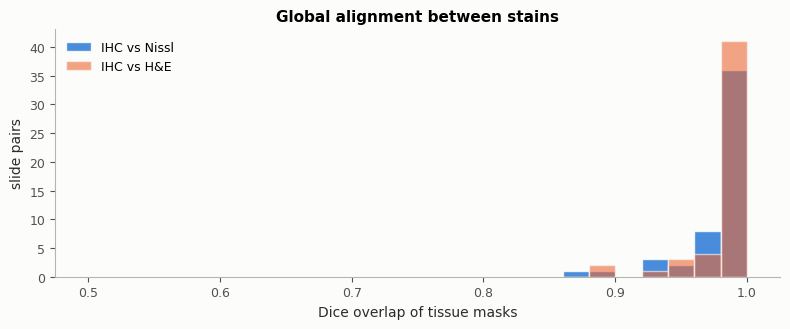

     dice_nissl  dice_he
min       0.874    0.883
50%       0.985    0.988
max       0.992    0.996


In [7]:
def tissue_dice(pair):
    masks = {s: su.tissue_mask(su.fetch_thumbnail(pair[s], 1024)[0]) for s in STAINS}
    dice = lambda a, b: 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)
    return dice(masks["IHC"], masks["N"]), dice(masks["IHC"], masks["HE"])


with ThreadPoolExecutor(max_workers=8) as ex:
    pairs[["dice_nissl", "dice_he"]] = list(ex.map(tissue_dice, [r for _, r in pairs.iterrows()]))

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(min(0.5, pairs[["dice_nissl", "dice_he"]].min().min()), 1, 26)
ax.hist(pairs.dice_nissl, bins=bins, color="#2a78d6", alpha=0.85, label="IHC vs Nissl", edgecolor="#fcfcfb")
ax.hist(pairs.dice_he, bins=bins, color="#eb6834", alpha=0.6, label="IHC vs H&E", edgecolor="#fcfcfb")
ax.set_xlabel("Dice overlap of tissue masks")
ax.set_ylabel("slide pairs")
ax.set_title("Global alignment between stains")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(pairs[["dice_nissl", "dice_he"]].describe().loc[["min", "50%", "max"]].round(3))

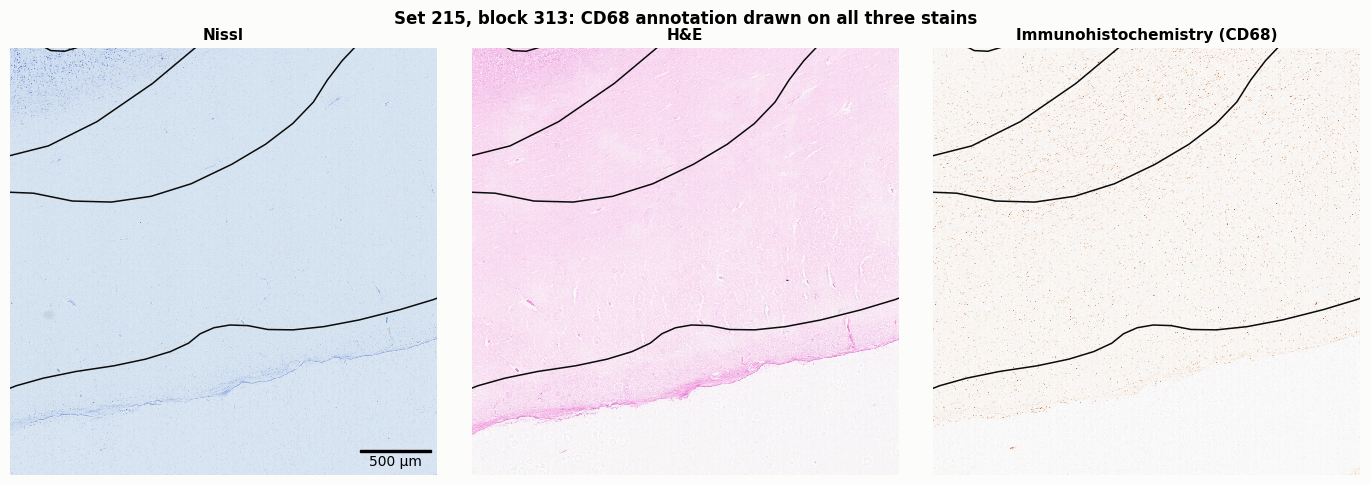

In [8]:
example = pairs.loc[pairs.dice_nissl.idxmax()]
annotations = su.load_annotations(example.annotation_url)
largest = max(annotations, key=lambda a: a["geometry"].area)["geometry"]
inside = largest.representative_point()            # guaranteed to lie inside the polygon
cx, cy = inside.x, inside.y
field = 3000 / su.MPP_LEVEL0

fig, axes = plt.subplots(1, 3, figsize=(14, 4.9))
for ax, stain in zip(axes, STAINS):
    img, reg = su.fetch_region(example[stain], cx - field / 2, cy - field / 2, field, field, downsample=6)
    ax.imshow(img)
    su.draw_annotation_outlines(ax, annotations, reg, colors={g: "#0b0b0b" for g in range(1, 4)}, linewidth=1.1)
    ax.set_title(f"{su.STAIN_LABELS[stain]}" + (f" ({PROTEIN})" if stain == "IHC" else ""))
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0)
    ax.axis("off")
su.scale_bar(axes[0], reg, 0.5)
plt.suptitle(f"Set {example.set_id}, block {example.biosample}: {PROTEIN} annotation drawn on all three stains",
             fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Matched tiles

### 3.1 Sampling

Positive windows lie entirely inside the annotation and negative windows entirely outside it. Every tile in a window inherits the window's label. Windows that straddle the boundary are never sampled, which keeps the labels clean despite the small offset between neighbouring sections. The test is therefore *clearly inside versus clearly outside*; boundary tiles are evaluated in Section 6.

In [9]:
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    windows = pd.DataFrame([w for ws in ex.map(lambda r: sample_windows(r, WINDOWS_PER_CLASS),
                                               [r for _, r in pairs.iterrows()]) for w in ws])
tiles = windows.loc[windows.index.repeat(WINDOW * WINDOW)].reset_index(names="window")
tiles["position"] = np.tile(np.arange(WINDOW * WINDOW), len(windows))
print(f"{len(windows)} windows -> {len(tiles)} tiles in {time.time() - t0:.0f} s")
tiles.groupby(["biosample", "label"]).size().unstack().rename(columns={0: "negative", 1: "positive"})

612 windows -> 9792 tiles in 11 s


label,negative,positive
biosample,,
217,480,480
218,768,768
313,1056,1056
314,2016,2016
315,576,576


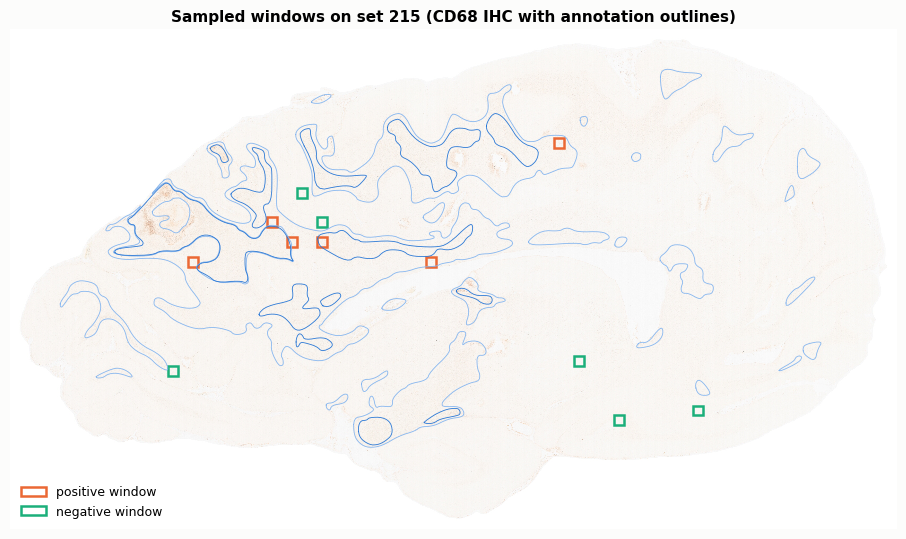

In [10]:
slide_windows = windows[windows.set_id == example.set_id]
thumb, treg = su.fetch_region(example.IHC, *su.tissue_bbox(example.IHC), downsample=48)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.imshow(thumb)
su.draw_annotation_outlines(ax, annotations, treg, linewidth=0.6)
for _, w in slide_windows.iterrows():
    c, r = treg.to_pixels(w.x, w.y)
    color = "#eb6834" if w.label else "#1baf7a"
    ax.add_patch(Rectangle((c, r), WINDOW_L0 / treg.downsample, WINDOW_L0 / treg.downsample,
                           fill=False, ec=color, lw=1.8))
ax.legend(handles=[Patch(fill=False, ec="#eb6834", lw=1.8, label="positive window"),
                   Patch(fill=False, ec="#1baf7a", lw=1.8, label="negative window")], loc="lower left")
ax.set_title(f"Sampled windows on set {example.set_id} ({PROTEIN} IHC with annotation outlines)")
ax.axis("off")
plt.tight_layout()
plt.show()

### 3.2 What the tiles look like

Four positive and four negative tiles from different slides, each shown on the three stains. The IHC column shows what the label is based on; the Nissl and H&E columns show what the classifier will see.

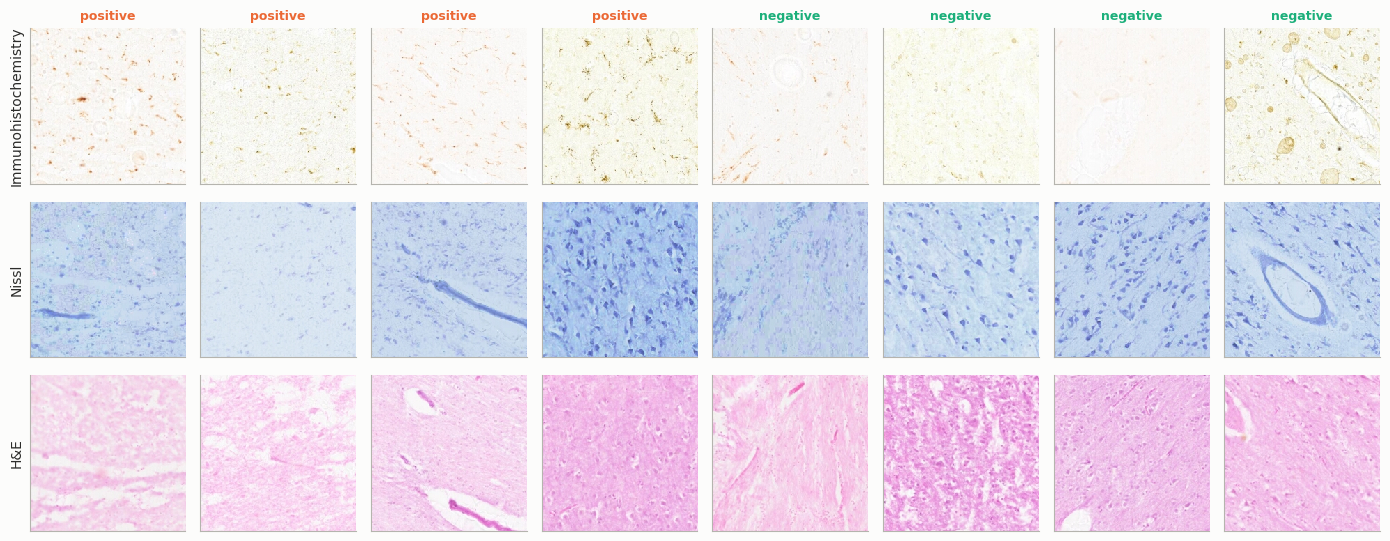

In [11]:
gallery_rng = np.random.default_rng(RANDOM_SEED)
picks = pd.concat([w.drop_duplicates("set_id").sample(4, random_state=RANDOM_SEED)
                   for _, w in windows.groupby("label")]).sort_values("label", ascending=False)

fig, axes = plt.subplots(3, len(picks), figsize=(1.75 * len(picks), 5.6))
for c, (_, w) in enumerate(picks.iterrows()):
    pos = gallery_rng.integers(WINDOW * WINDOW)
    for r, stain in enumerate(["IHC", "N", "HE"]):
        axes[r, c].imshow(split_window(fetch_window(w, stain))[pos])
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
    axes[0, c].set_title("positive" if w.label else "negative", fontsize=9,
                         color="#eb6834" if w.label else "#1baf7a", fontweight="bold")
for r, stain in enumerate(["IHC", "N", "HE"]):
    axes[r, 0].set_ylabel(su.STAIN_LABELS[stain], fontsize=10)
plt.tight_layout()
plt.show()

## 4. Features

Each stain is downloaded and passed through the encoder immediately. Only the feature vectors are kept, so memory use stays low. Images remain in the on-disk cache and are re-read when a figure needs them.

In [12]:
encoder = Encoder(ENCODER)
print(f"{ENCODER}: {sum(p.numel() for p in encoder.model.parameters()) / 1e6:.0f} M parameters on {DEVICE}")

features = {}
for stain in STAINS:
    t0 = time.time()
    images = fetch_tiles(windows, stain)
    t1 = time.time()
    features[f"Phikon-v2 · {su.STAIN_LABELS[stain]}"] = encoder(images)
    features[f"colour · {su.STAIN_LABELS[stain]}"] = colour_features(images)
    print(f"{su.STAIN_LABELS[stain]:>22}: {len(images)} tiles, download {t1 - t0:.0f} s, "
          f"features {time.time() - t1:.0f} s")
    del images

y = tiles.label.to_numpy()
blocks = tiles.biosample.to_numpy()

owkin/phikon-v2: 303 M parameters on cuda
                 Nissl: 9792 tiles, download 2 s, features 83 s
                   H&E: 9792 tiles, download 1 s, features 83 s
  Immunohistochemistry: 9792 tiles, download 1 s, features 84 s


### 4.1 A first look at the feature space

A t-SNE projection of the Nissl features of a random subset of tiles. In the left panel, colour shows the label; in the right panel, colour shows the block. Positive and negative tiles that separate in the projection indicate a signal a linear probe can use. Clusters that follow blocks instead indicate **batch effects**: differences in cutting, staining or scanning between blocks. Leave-one-block-out validation is designed to expose these.

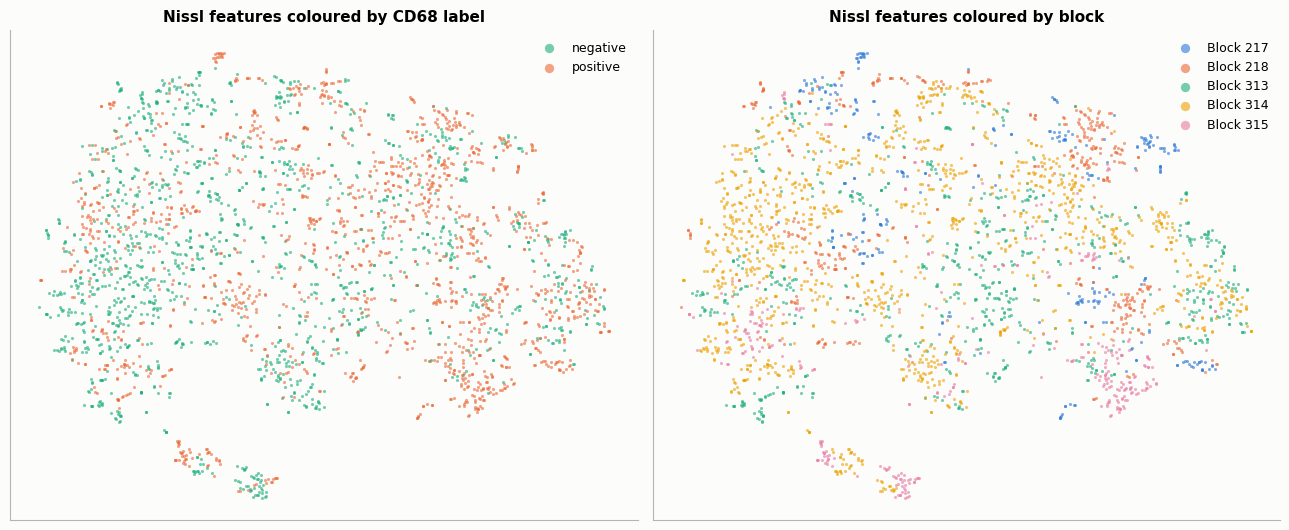

In [13]:
subset = np.random.default_rng(RANDOM_SEED).choice(len(y), min(3000, len(y)), replace=False)
emb = TSNE(n_components=2, init="pca", perplexity=40, random_state=RANDOM_SEED).fit_transform(
    PCA(n_components=50, random_state=RANDOM_SEED).fit_transform(
        StandardScaler().fit_transform(features["Phikon-v2 · Nissl"][subset])))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for label, color, name in [(0, "#1baf7a", "negative"), (1, "#eb6834", "positive")]:
    m = y[subset] == label
    axes[0].scatter(emb[m, 0], emb[m, 1], s=5, color=color, alpha=0.6, lw=0, label=name)
axes[0].set_title(f"Nissl features coloured by {PROTEIN} label")
axes[0].legend(markerscale=3)
block_colors = dict(zip(sorted(np.unique(blocks)), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
for b, color in block_colors.items():
    m = blocks[subset] == b
    axes[1].scatter(emb[m, 0], emb[m, 1], s=5, color=color, alpha=0.6, lw=0, label=f"Block {b}")
axes[1].set_title("Nissl features coloured by block")
axes[1].legend(markerscale=3)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 5. Held-out evaluation

Every feature set is evaluated with the same leave-one-block-out protocol. The AUC is computed separately for each held-out block. Each dot below is one block, and the bar is the mean over blocks. The two reference rows use the IHC tile itself: they show how well the annotation can be recovered when the protein stain *is* visible, which bounds what the routine stains can be expected to achieve.

In [14]:
results, oof = [], {}
for name, X in features.items():
    aucs, proba = evaluate_by_block(X, y, blocks)
    oof[name] = proba
    results += [{"features": name, "block": b, "auc": a} for b, a in aucs.items()]
results = pd.DataFrame(results)
summary_table = results.pivot_table(index="features", columns="block", values="auc")
summary_table["mean"] = summary_table.mean(axis=1)
summary_table = summary_table.sort_values("mean", ascending=False)
summary_table

block,217,218,313,314,315,mean
features,,,,,,
Phikon-v2 · Immunohistochemistry,0.908,0.942,0.906,0.895,0.954,0.921
colour · Immunohistochemistry,0.845,0.824,0.892,0.848,0.947,0.871
Phikon-v2 · H&E,0.843,0.756,0.717,0.636,0.768,0.744
Phikon-v2 · Nissl,0.812,0.753,0.707,0.585,0.760,0.723
colour · H&E,0.813,0.729,0.694,0.594,0.737,0.713
colour · Nissl,0.846,0.680,0.685,0.492,0.741,0.689


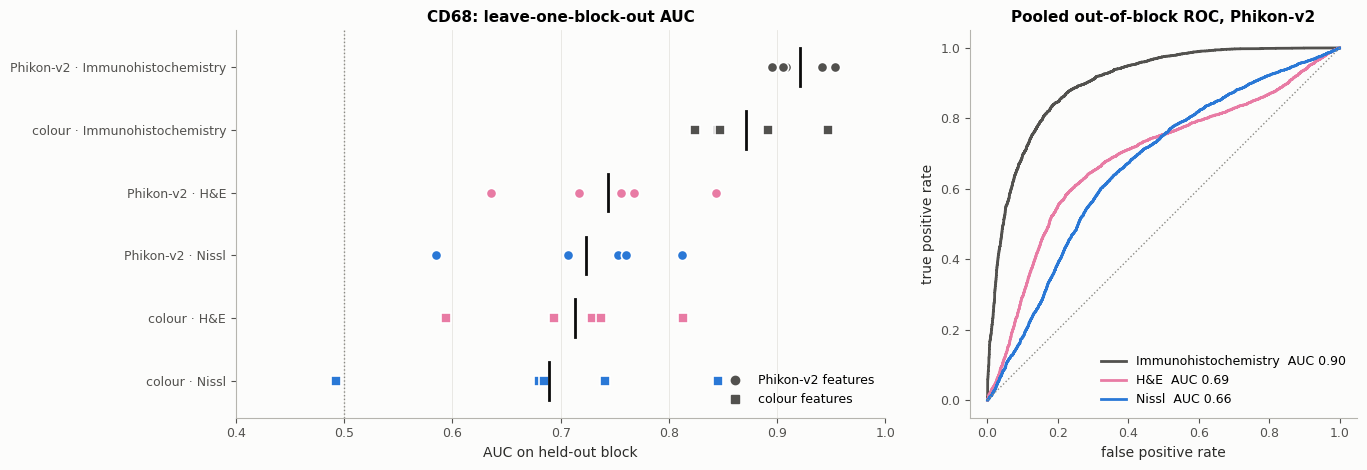

In [15]:
FEATURE_COLORS = {"Nissl": "#2a78d6", "H&E": "#e87ba4", "Immunohistochemistry": "#52514e"}
order = summary_table.index[::-1].tolist()

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 0.5 * len(order) + 1.8), gridspec_kw={"width_ratios": [1.5, 1]})
for i, name in enumerate(order):
    stain = name.split(" · ")[1]
    vals = results.loc[results.features == name, "auc"]
    marker = "o" if name.startswith("Phikon") else "s"
    ax.scatter(vals, np.full(len(vals), i), s=55, color=FEATURE_COLORS[stain], marker=marker,
               edgecolor="white", lw=1.2, zorder=3)
    ax.plot([vals.mean()] * 2, [i - 0.3, i + 0.3], color="#0b0b0b", lw=2, zorder=4)
ax.axvline(0.5, ls=":", color="#8a8984", lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("AUC on held-out block")
ax.set_title(f"{PROTEIN}: leave-one-block-out AUC")
ax.grid(axis="x")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#52514e", label="Phikon-v2 features"),
                   Line2D([], [], marker="s", ls="", color="#52514e", label="colour features")],
          loc="lower right")

for name in [n for n in summary_table.index if n.startswith("Phikon")]:
    stain = name.split(" · ")[1]
    ok = ~np.isnan(oof[name])
    fpr, tpr, _ = roc_curve(y[ok], oof[name][ok])
    ax2.plot(fpr, tpr, lw=2, color=FEATURE_COLORS[stain],
             label=f"{stain}  AUC {roc_auc_score(y[ok], oof[name][ok]):.2f}")
ax2.plot([0, 1], [0, 1], ls=":", color="#8a8984", lw=1)
ax2.set_xlabel("false positive rate")
ax2.set_ylabel("true positive rate")
ax2.set_title("Pooled out-of-block ROC, Phikon-v2")
ax2.legend(loc="lower right")
ax2.set_aspect("equal")
plt.tight_layout()
plt.show()

**Reading the evaluation (CD68, default settings).**

* **The label is learnable when the protein is visible.** With the IHC tile as input, Phikon-v2 features reach a mean held-out AUC of about 0.92, ahead of colour statistics at about 0.87. The labels are therefore consistent, and the foundation-model features capture the relevant appearance.
* **Routine stains carry part of the signal.** From H&E and Nissl, the AUC falls to about 0.74 and 0.72. That is above chance on every held-out block, but far below the reference.
* **The foundation model adds little over colour here.** Colour statistics of the same tiles reach about 0.71 (H&E) and 0.69 (Nissl). Most of what the routine stains reveal about CD68 at this scale is coarse tissue appearance, not cellular detail that only a deep model would resolve. Section 7 shows what that appearance is.
* **Blocks differ.** Block 314 is the hardest held-out block for both routine stains, and block 217 the easiest, although block 217 contributes only five slides.

## 6. A virtual IHC map

The sampled tiles were all clearly inside or clearly outside the annotation. A map shows how the classifier behaves on *every* tile of a contiguous field, boundaries included. The classifier is trained on all blocks except `MAP_BLOCK`. It is then applied to every tissue tile of a `MAP_FIELD_MM` field of a slide from that block, using only the routine stain `MAP_STAIN`. The slide with the most annotated tissue in that block is used, and the field is placed where annotated and unannotated tissue are most evenly mixed.

In [16]:
map_name = f"Phikon-v2 · {su.STAIN_LABELS[MAP_STAIN]}"
train = blocks != MAP_BLOCK
inner = [(np.flatnonzero(blocks[train] != b), np.flatnonzero(blocks[train] == b)) for b in np.unique(blocks[train])]
map_probe = make_probe(features[map_name].shape[1], inner).fit(features[map_name][train], y[train])

candidates = pairs[pairs.biosample == MAP_BLOCK].copy()
candidates["annotated_mm2"] = [sum(a["geometry"].area for a in su.load_annotations(u)) * su.MPP_LEVEL0 ** 2 / 1e6
                               for u in candidates.annotation_url]
map_pair = candidates.sort_values("annotated_mm2", ascending=False).iloc[0]
map_annotations = su.load_annotations(map_pair.annotation_url)

# Field placement: among all positions with mostly tissue, the one whose annotated share is closest to one half.
n_tiles = int(MAP_FIELD_MM * 1000 / su.MPP_LEVEL0 // TILE_L0)
n_tiles -= n_tiles % 8
annotated_grid, tissue_grid, grid_region = label_grid(map_pair, cells_per_tile=1)
ann_share = uniform_filter(annotated_grid * tissue_grid, n_tiles) / np.maximum(uniform_filter(tissue_grid, n_tiles), 1e-6)
score = np.where(uniform_filter(tissue_grid, n_tiles) >= 0.6, np.abs(ann_share - 0.5), np.inf)
r_c, c_c = np.unravel_index(np.argmin(score), score.shape)
x0 = grid_region.x0 + (c_c - n_tiles // 2) * TILE_L0
y0 = grid_region.y0 + (r_c - n_tiles // 2) * TILE_L0
grid = su.Region(x0, y0, TILE_L0, (n_tiles, n_tiles))
print(f"Set {map_pair.set_id}, block {map_pair.biosample}, section {map_pair.section}: "
      f"{n_tiles} x {n_tiles} tiles of {TILE_L0 * su.MPP_LEVEL0:.0f} um")

# Download the field in 8 x 8-tile chunks, keep tissue tiles only, and embed them.
chunks = [(r, c) for r in range(0, n_tiles, 8) for c in range(0, n_tiles, 8)]
def fetch_chunk(rc):
    r, c = rc
    img, _ = su.fetch_region(map_pair[MAP_STAIN], x0 + c * TILE_L0, y0 + r * TILE_L0, 8 * TILE_L0, 8 * TILE_L0,
                             downsample=DOWNSAMPLE)
    return r, c, split_window(img, 8)

t0 = time.time()
prob_map = np.full((n_tiles, n_tiles), np.nan)
with ThreadPoolExecutor(max_workers=16) as ex:
    for r, c, chunk_tiles in ex.map(fetch_chunk, chunks):
        tissue = np.array([su.tissue_mask(t, sigma=0).mean() for t in chunk_tiles]) >= MIN_TISSUE
        if tissue.any():
            p = map_probe.predict_proba(encoder(chunk_tiles[tissue]))[:, 1]
            idx = np.flatnonzero(tissue)
            prob_map[r + idx // 8, c + idx % 8] = p
print(f"Predicted {np.isfinite(prob_map).sum()} tissue tiles in {time.time() - t0:.0f} s")

Set 87, block 314, section 455: 64 x 64 tiles of 224 um
Predicted 4096 tissue tiles in 28 s


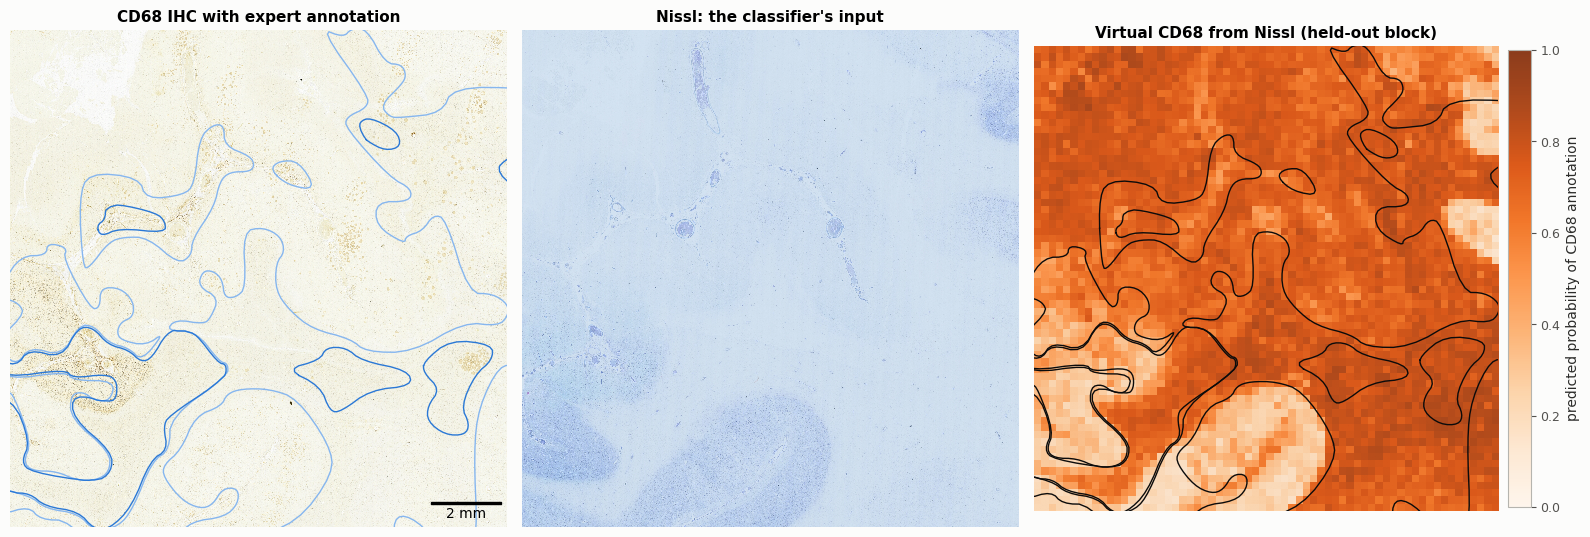

Field AUC (all tissue tiles, boundary tiles excluded): 0.487


In [17]:
ihc_field, field_reg = su.fetch_region(map_pair.IHC, x0, y0, n_tiles * TILE_L0, n_tiles * TILE_L0, downsample=16)
routine_field, _ = su.fetch_region(map_pair[MAP_STAIN], x0, y0, n_tiles * TILE_L0, n_tiles * TILE_L0, downsample=16)
annotated_frac = su.tile_reduce(su.rasterize_annotations(map_annotations, field_reg, "binary").astype(np.float32),
                                int(TILE_L0 / 16))[:n_tiles, :n_tiles]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(ihc_field)
su.draw_annotation_outlines(axes[0], map_annotations, field_reg, linewidth=1)
axes[0].set_title(f"{PROTEIN} IHC with expert annotation")
axes[1].imshow(routine_field)
axes[1].set_title(f"{su.STAIN_LABELS[MAP_STAIN]}: the classifier's input")
extent = (0, routine_field.shape[1], routine_field.shape[0], 0)
axes[2].imshow(routine_field, alpha=0.35)
h = axes[2].imshow(prob_map, cmap="Oranges", vmin=0, vmax=1, alpha=0.9, extent=extent)
su.draw_annotation_outlines(axes[2], map_annotations, field_reg, colors={g: "#0b0b0b" for g in range(1, 4)},
                            linewidth=1)
plt.colorbar(h, ax=axes[2], fraction=0.046, pad=0.02, label=f"predicted probability of {PROTEIN} annotation")
axes[2].set_title(f"Virtual {PROTEIN} from {su.STAIN_LABELS[MAP_STAIN]} (held-out block)")
for ax in axes:
    ax.set_xlim(0, routine_field.shape[1]); ax.set_ylim(routine_field.shape[0], 0)
    ax.axis("off")
su.scale_bar(axes[0], field_reg, 2)
plt.tight_layout()
plt.show()

valid = np.isfinite(prob_map) & ((annotated_frac >= 0.5) | (annotated_frac <= 0.05))
print(f"Field AUC (all tissue tiles, boundary tiles excluded): "
      f"{roc_auc_score(annotated_frac[valid] >= 0.5, prob_map[valid]):.3f}")

**Reading the map.** In the default field (block 314, the hardest held-out block in Section 5), the field AUC is close to chance. The map still shows clearly what the classifier responds to. Probability is high across pale, cell-sparse tissue, largely white matter in the Nissl image, and low over the darker, neuron-dense grey matter at the lower left, *whatever* the expert outlines say. In this field the CD68 annotations cross both tissue types, so a rule based on tissue type fails.

*To explore:* set `MAP_BLOCK = 217` or `218`, where held-out performance was higher, or `MAP_STAIN = "HE"`, and compare the maps.

## 7. What the classifier responds to

The out-of-block predictions from Section 5 can be sorted to show the tiles the Nissl classifier is most confident about, and the tiles where it is most wrong. Each tile is shown on Nissl (the input) above the IHC section (the evidence for the label).

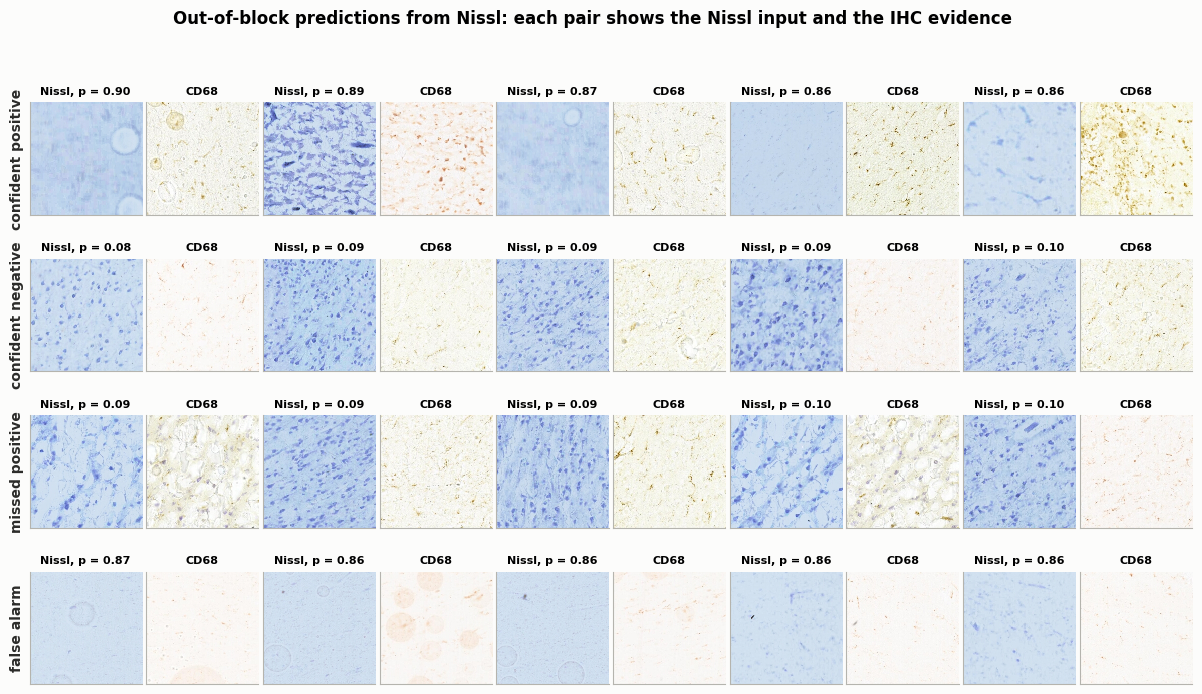

In [18]:
name = "Phikon-v2 · Nissl"
p = oof[name]
groups = {
    "confident positive": np.flatnonzero(y == 1)[np.argsort(-p[y == 1])][:5],
    "confident negative": np.flatnonzero(y == 0)[np.argsort(p[y == 0])][:5],
    "missed positive": np.flatnonzero(y == 1)[np.argsort(p[y == 1])][:5],
    "false alarm": np.flatnonzero(y == 0)[np.argsort(-p[y == 0])][:5],
}

fig, axes = plt.subplots(len(groups), 10, figsize=(15, 1.75 * len(groups) + 0.6),
                         gridspec_kw={"wspace": 0.04, "hspace": 0.35})
for g, (title, idx) in enumerate(groups.items()):
    for k, i in enumerate(idx):
        t = tiles.iloc[i]
        w = windows.loc[t.window]
        for j, stain in enumerate(["N", "IHC"]):
            ax = axes[g, 2 * k + j]
            ax.imshow(split_window(fetch_window(w, stain))[t.position])
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"Nissl, p = {p[i]:.2f}" if j == 0 else PROTEIN, fontsize=8)
    axes[g, 0].set_ylabel(title, fontsize=10, fontweight="bold")
plt.suptitle("Out-of-block predictions from Nissl: each pair shows the Nissl input and the IHC evidence",
             fontweight="bold", y=1.0)
plt.show()

**Reading the gallery.** The four groups tell a consistent story.

* **Confident positives** are pale, cell-poor Nissl tiles, typical of white matter.
* **Confident negatives** are neuron-rich grey matter.
* **Missed positives** are neuron-rich tiles whose IHC section does show CD68-positive cells. Microglial activation within grey matter has no obvious Nissl counterpart at this scale.
* **False alarms** are pale tissue without a CD68 annotation.

The classifier has therefore learned mainly a **tissue-type prior**: in this dataset, CD68 annotations are concentrated in white matter, as the overview in `07_ihc_stain_quantification_vs_annotations.ipynb` also suggests. This is a confound, not a readout of microglial activation, and it explains why the foundation model barely improves on colour statistics. A fair test of virtual IHC must control for it. One option is to evaluate within white matter and within grey matter separately. The myelin section in each set provides a white-matter mask for that purpose.

## 8. Comparison across proteins

The same pipeline is repeated for the proteins in `COMPARE_PROTEINS`, on up to `COMPARE_MAX_SLIDES` slides each with `COMPARE_WINDOWS_PER_CLASS` windows per class and slide. The results are combined with those for `PROTEIN`. Each protein takes roughly 5 minutes on a first run. The question is which pathological processes leave a footprint on routine stains strong enough for a linear probe to read.

In [19]:
def protein_results(protein, windows_per_class, max_slides):
    p = matched_pairs(catalog, protein)
    if len(p) > max_slides:
        p = p.sample(max_slides, random_state=RANDOM_SEED).reset_index(drop=True)
    with ThreadPoolExecutor(max_workers=8) as ex:
        w = pd.DataFrame([x for ws in ex.map(lambda r: sample_windows(r, windows_per_class),
                                             [r for _, r in p.iterrows()]) for x in ws])
    labels = np.repeat(w.label.to_numpy(), WINDOW * WINDOW)
    groups = np.repeat(w.biosample.to_numpy(), WINDOW * WINDOW)
    rows = []
    for stain in STAINS:
        images = fetch_tiles(w, stain)
        for kind, X in (("Phikon-v2", encoder(images)), ("colour", colour_features(images))):
            aucs, _ = evaluate_by_block(X, labels, groups)
            rows += [{"protein": protein, "stain": su.STAIN_LABELS[stain], "features": kind, "block": b, "auc": a}
                     for b, a in aucs.items()]
        del images
    print(f"{protein:>6}: {len(p)} slides, {len(labels)} tiles")
    return rows


comparison = [{"protein": PROTEIN, "stain": n.split(" · ")[1], "features": n.split(" · ")[0], "block": r.block,
               "auc": r.auc} for n in features for r in results[results.features == n].itertuples()]
for protein in COMPARE_PROTEINS:
    t0 = time.time()
    comparison += protein_results(protein, COMPARE_WINDOWS_PER_CLASS, COMPARE_MAX_SLIDES)
    print(f"        {time.time() - t0:.0f} s")
comparison = pd.DataFrame(comparison)
comparison_table = (comparison.groupby(["protein", "features", "stain"]).auc.mean()
                    .unstack(["features", "stain"]).round(3))
comparison_table

   FIB: 24 slides, 2064 tiles
        63 s
  GFAP: 24 slides, 2208 tiles
        71 s
 HIF1a: 24 slides, 2192 tiles
        67 s


features Phikon-v2                            colour                       \
stain          H&E Immunohistochemistry Nissl    H&E Immunohistochemistry   
protein                                                                     
CD68         0.744                0.921 0.723  0.713                0.871   
FIB          0.614                0.862 0.777  0.651                0.916   
GFAP         0.676                0.895 0.588  0.664                0.764   
HIF1a        0.730                0.982 0.735  0.679                0.989   

features        
stain    Nissl  
protein         
CD68     0.689  
FIB      0.743  
GFAP     0.649  
HIF1a    0.682

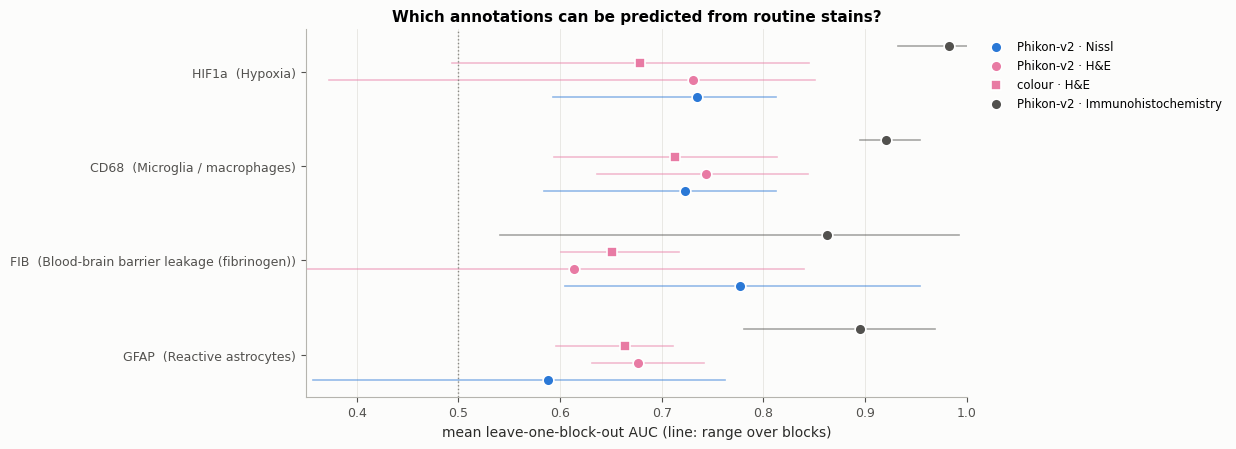

In [20]:
proteins = comparison.groupby("protein").auc.mean().sort_values().index.tolist()
series = [("Phikon-v2", "Nissl"), ("Phikon-v2", "H&E"), ("colour", "H&E"), ("Phikon-v2", "Immunohistochemistry")]
offsets = np.linspace(-0.27, 0.27, len(series))

fig, ax = plt.subplots(figsize=(12.5, 0.75 * len(proteins) + 1.6))
for (kind, stain), dy in zip(series, offsets):
    sub = comparison[(comparison.features == kind) & (comparison.stain == stain)]
    means = sub.groupby("protein").auc.mean().reindex(proteins)
    color = FEATURE_COLORS[stain]
    marker = "o" if kind == "Phikon-v2" else "s"
    ax.scatter(means, np.arange(len(proteins)) + dy, s=60, color=color, marker=marker, edgecolor="white",
               lw=1.2, zorder=3, label=f"{kind} · {stain}")
    for i, protein in enumerate(proteins):
        vals = sub[sub.protein == protein].auc
        if len(vals):
            ax.plot([vals.min(), vals.max()], [i + dy] * 2, color=color, lw=1.2, alpha=0.5)
ax.axvline(0.5, ls=":", color="#8a8984", lw=1)
ax.set_yticks(range(len(proteins)), [f"{p}  ({su.PROTEIN_INFO[p]['marker']})" for p in proteins])
ax.set_xlim(0.35, 1.0)
ax.set_xlabel("mean leave-one-block-out AUC (line: range over blocks)")
ax.set_title("Which annotations can be predicted from routine stains?")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=8.5)
ax.grid(axis="x")
plt.tight_layout()
plt.show()

**Reading the comparison.** Four observations, using the default settings. The three additional proteins use a reduced sample, so differences of a few hundredths are within noise.

1. **Every annotation is learnable from its own IHC stain** (AUC about 0.86–0.98). For HIF1a and fibrinogen, colour statistics alone already reach about 0.92–0.99, in line with the stain-intensity analysis in `07_ihc_stain_quantification_vs_annotations.ipynb`.
2. **From routine stains, no protein comes close to that reference.** The AUCs range from about 0.59 to 0.78. Fibrinogen from Nissl and HIF1a from either routine stain are among the highest, plausibly because both concentrate in and around the infarct, which is visible on routine stains. GFAP from Nissl is the weakest.
3. **The foundation model's advantage over colour statistics is small and not consistent.** It is ahead for most protein–stain combinations, but behind for GFAP on Nissl and for fibrinogen on H&E.
4. **The spread between held-out blocks is wide** (the horizontal lines). With five blocks from a single case, block-to-block variation dominates the uncertainty.

## 9. Summary and limitations

### Findings
* The three stains of each set are well aligned (median tissue-mask Dice about 0.99), so IHC annotations can serve as labels for Nissl and H&E tiles at the 224 µm scale.
* Under leave-one-block-out validation, expert annotations are recovered well from the IHC tile itself (AUC about 0.86–0.98) but only partially from Nissl or H&E (about 0.59–0.78).
* On routine stains, Phikon-v2 features improve only marginally on colour statistics. For CD68, the virtual map and the galleries show that the classifier mainly learned the tissue type (white versus grey matter) in which annotations are common. That is a confound, not evidence of microglial activation.
* With frozen features and a linear probe, virtual IHC from routine stains is not reliable for these markers in this case. The notebook provides the data pipeline and evaluation framework for testing stronger approaches honestly.

### Limitations
* **Labels come from a neighbouring section** 40–60 µm away. Correspondence is regional, not cellular.
* **Clean windows are easier than real use.** Sampled windows lie entirely inside or outside the annotations. The contiguous field in Section 6 includes boundaries and is harder.
* **One case and five blocks.** Per-block AUCs carry wide uncertainty, and blocks differ in size and annotation density.
* **Domain shift.** Phikon-v2 was trained on cancer histology, largely H&E. Nissl-stained brain tissue lies outside its training distribution.
* **Linear probing only.** Fine-tuning, multi-scale context or tissue-type-aware models could do better, at the cost of the simplicity and runtime that make this notebook runnable on a free GPU.

### Things to try
* `MAP_BLOCK = 217`, or `MAP_STAIN = "HE"`, to compare virtual maps across blocks and stains.
* `DOWNSAMPLE = 4` to give each tile 448 µm of context.
* Control for tissue type: fetch the myelin slide of each set (`su.slide_set(catalog, set_id)`, stain `"M"`), threshold it into a white-matter mask, and evaluate within each tissue class.
* `ENCODER = "owkin/phikon"`, the smaller ViT-B predecessor, for a faster run. Encoders distributed as `timm` models, such as UNI2-h, Virchow2 or H-optimus-0 (all gated), need a small change to the `Encoder` class.

### Reference
Filiot, A. et al. (2024). Phikon-v2, a large and public feature extractor for biomarker prediction. *arXiv:2409.09173*.